# Lösung: Objekterkennung bewerten

1. Precision, Recall und Average Precision **von Hand** berechnen
2. Das trainierte Modell mit `model.val()` auf den Testdaten bewerten
3. Eine anwendungsnahe Metrik für den KI-Geldzähler: Stimmt der **Betrag**?

## Umgebung

Die Notebooks laufen lokal oder in Google Colab. Für Colab `use_colab = True` setzen und unter *Laufzeit > Laufzeittyp ändern* eine GPU wählen.

Die Version von `ultralytics` ist festgelegt, damit die Notebooks auch in späteren Semestern laufen.

In [1]:
use_colab = False

if use_colab:
    %pip install -q ultralytics==8.4.215
    from google.colab import drive
    drive.mount("/content/drive")
    base_path = "/content/drive/MyDrive"
else:
    # lokal einmalig installieren: pip install ultralytics==8.4.215
    base_path = ".."

import ultralytics
ultralytics.checks()

Ultralytics 8.4.215 🚀 Python-3.13.18 torch-2.15.0+cu132 CPU (Intel Xeon Processor @ 2.10GHz)


Setup complete ✅ (2 CPUs, 7.8 GB RAM, 231.7/252.0 GB disk)


## 1. Average Precision von Hand

Klasse 1 €, auf den Testbildern liegen **5** echte 1-€-Münzen. Das Modell liefert 8 Detektionen, absteigend nach Confidence sortiert. Eine Detektion ist ein **TP**, wenn sie eine noch nicht zugeordnete Münze mit $\operatorname{IoU} \geq 0{,}5$ trifft, sonst ein **FP**.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

conf = np.array([0.95, 0.91, 0.85, 0.80, 0.72, 0.60, 0.45, 0.30])
tp = np.array([1, 1, 0, 1, 1, 0, 0, 1])
n_gt = 5

cum_tp = np.cumsum(tp)
cum_fp = np.cumsum(1 - tp)
precision = cum_tp / (cum_tp + cum_fp)
recall = cum_tp / n_gt

pd.DataFrame({"Conf": conf, "TP": tp, "kum. TP": cum_tp, "kum. FP": cum_fp,
              "Precision": precision.round(3), "Recall": recall})

,Conf,TP,kum. TP,kum. FP,Precision,Recall
0,0.95,1,1,0,1.000,0.2
1,0.91,1,2,0,1.000,0.4
2,0.85,0,2,1,0.667,0.4
3,0.80,1,3,1,0.750,0.6
4,0.72,1,4,1,0.800,0.8
5,0.60,0,4,2,0.667,0.8
6,0.45,0,4,3,0.571,0.8
7,0.30,1,5,3,0.625,1.0


**Interpolation:** Für jeden Recall-Wert wird die höchste Precision verwendet, die bei gleichem oder höherem Recall erreicht wird. AP ist die Fläche unter dieser treppenförmigen Kurve.

AP@0.5 = 0.845


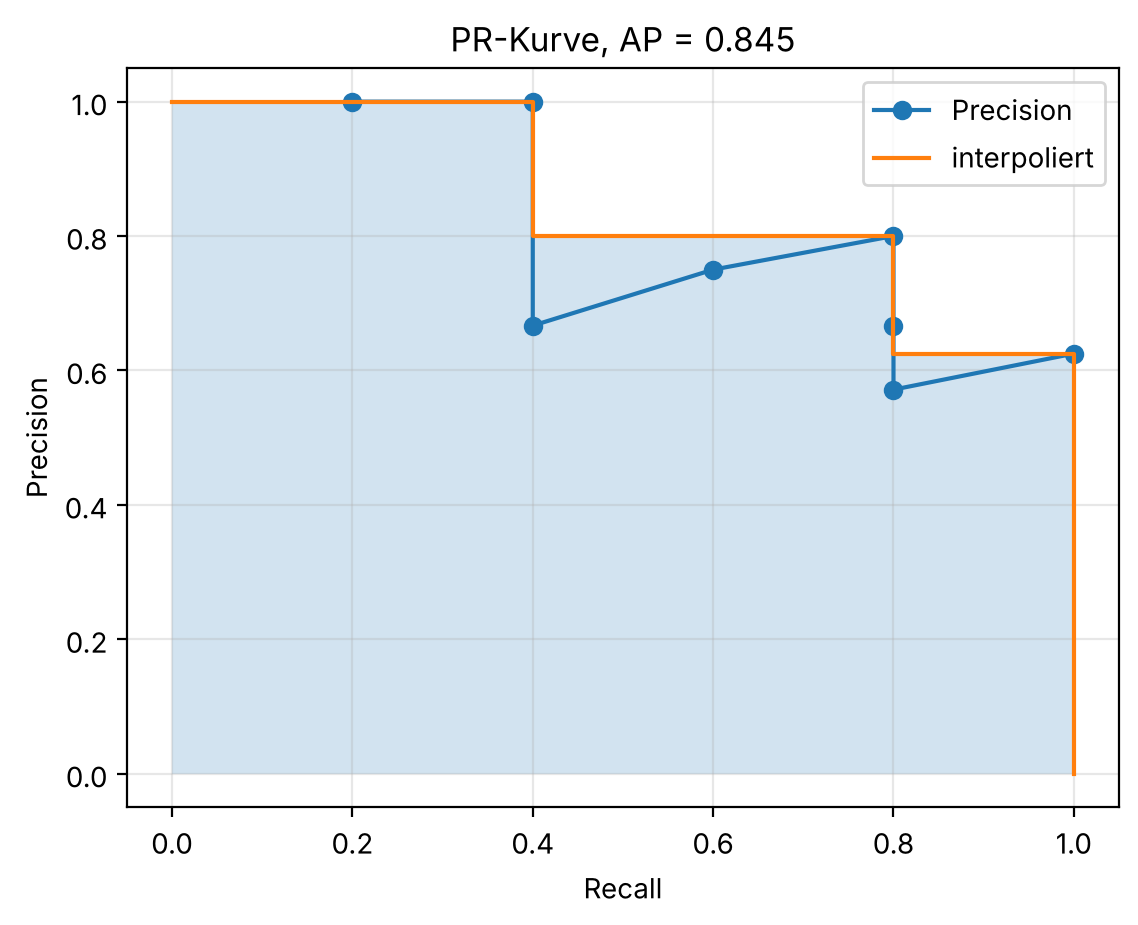

In [3]:
def average_precision(recall, precision):
    r = np.concatenate([[0], recall, [1]])
    p = np.concatenate([[1], precision, [0]])
    p_interp = np.maximum.accumulate(p[::-1])[::-1]    # Maximum von rechts
    idx = np.where(r[1:] != r[:-1])[0]
    return np.sum((r[idx + 1] - r[idx]) * p_interp[idx + 1]), r, p_interp


ap, r_curve, p_curve = average_precision(recall, precision)
print(f"AP@0.5 = {ap:.3f}")

plt.plot(recall, precision, "o-", label="Precision")
plt.step(r_curve, p_curve, where="pre", label="interpoliert")
plt.fill_between(r_curve, p_curve, step="pre", alpha=0.2)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title(f"PR-Kurve, AP = {ap:.3f}")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

- **mAP@0.5:** Mittelwert der AP über alle Klassen bei der IoU-Schwelle 0,5
- **mAP@0.5:0.95:** zusätzlich gemittelt über die IoU-Schwellen 0,50; 0,55; …; 0,95. Belohnt **genaue** Boxen.

## 2. Bewertung des trainierten Modells

In [4]:
import os
from pathlib import Path
from ultralytics import YOLO

DATA = os.path.join(base_path, "Datensätze", "muenzen_gesamt", "data.yaml")
MODEL_PATH = "runs/detect/muenzen/weights/best.pt"     # aus LösungYoloTraining.ipynb

model = YOLO(MODEL_PATH)
metrics = model.val(data=DATA, split="test", plots=True)
print(f"Precision {metrics.box.mp:.3f}, Recall {metrics.box.mr:.3f}")
print(f"mAP@0.5 {metrics.box.map50:.3f}, mAP@0.5:0.95 {metrics.box.map:.3f}")

Ultralytics 8.4.215 🚀 Python-3.13.18 torch-2.15.0+cu132 CPU (Intel Xeon Processor @ 2.10GHz)


YOLO26n summary (fused): 121 layers, 2,391,436 parameters, 0 gradients, 5.4 GFLOPs


val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1788.7±868.6 MB/s, size: 286.0 KB)


val: Scanning /root/t/code_ki1/Datensätze/muenzen_gesamt/labels/test.cache... 106 images, 19 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 106/106 15.3Mit/s 0.0s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 14% ━╸────────── 1/7 18.3s/it 5.5s<1:50

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 28% ━━━───────── 2/7 10.2s/it 10.5s<50.9s

... (13 outputs left out)

                  2eur         21         60       0.89      0.675       0.78      0.704


Speed: 11.6ms preprocess, 279.0ms inference, 0.0ms loss, 0.7ms postprocess per image


Results saved to /root/t/code_ki1/16_Objekterkennung/runs/detect/val


Precision 0.696, Recall 0.609
mAP@0.5 0.656, mAP@0.5:0.95 0.572


In [5]:
pd.DataFrame({"Klasse": [model.names[i] for i in range(len(model.names))],
              "AP@0.5:0.95": metrics.box.maps.round(3)})

,Klasse,AP@0.5:0.95
0,1ct,0.566
1,2ct,0.475
2,5ct,0.591
3,10ct,0.683
4,20ct,0.454
5,50ct,0.644
6,1eur,0.461
7,2eur,0.704


Die Konfusionsmatrix enthält eine zusätzliche Klasse **background**: übersehene Münzen (FN) und Fehlalarme (FP).

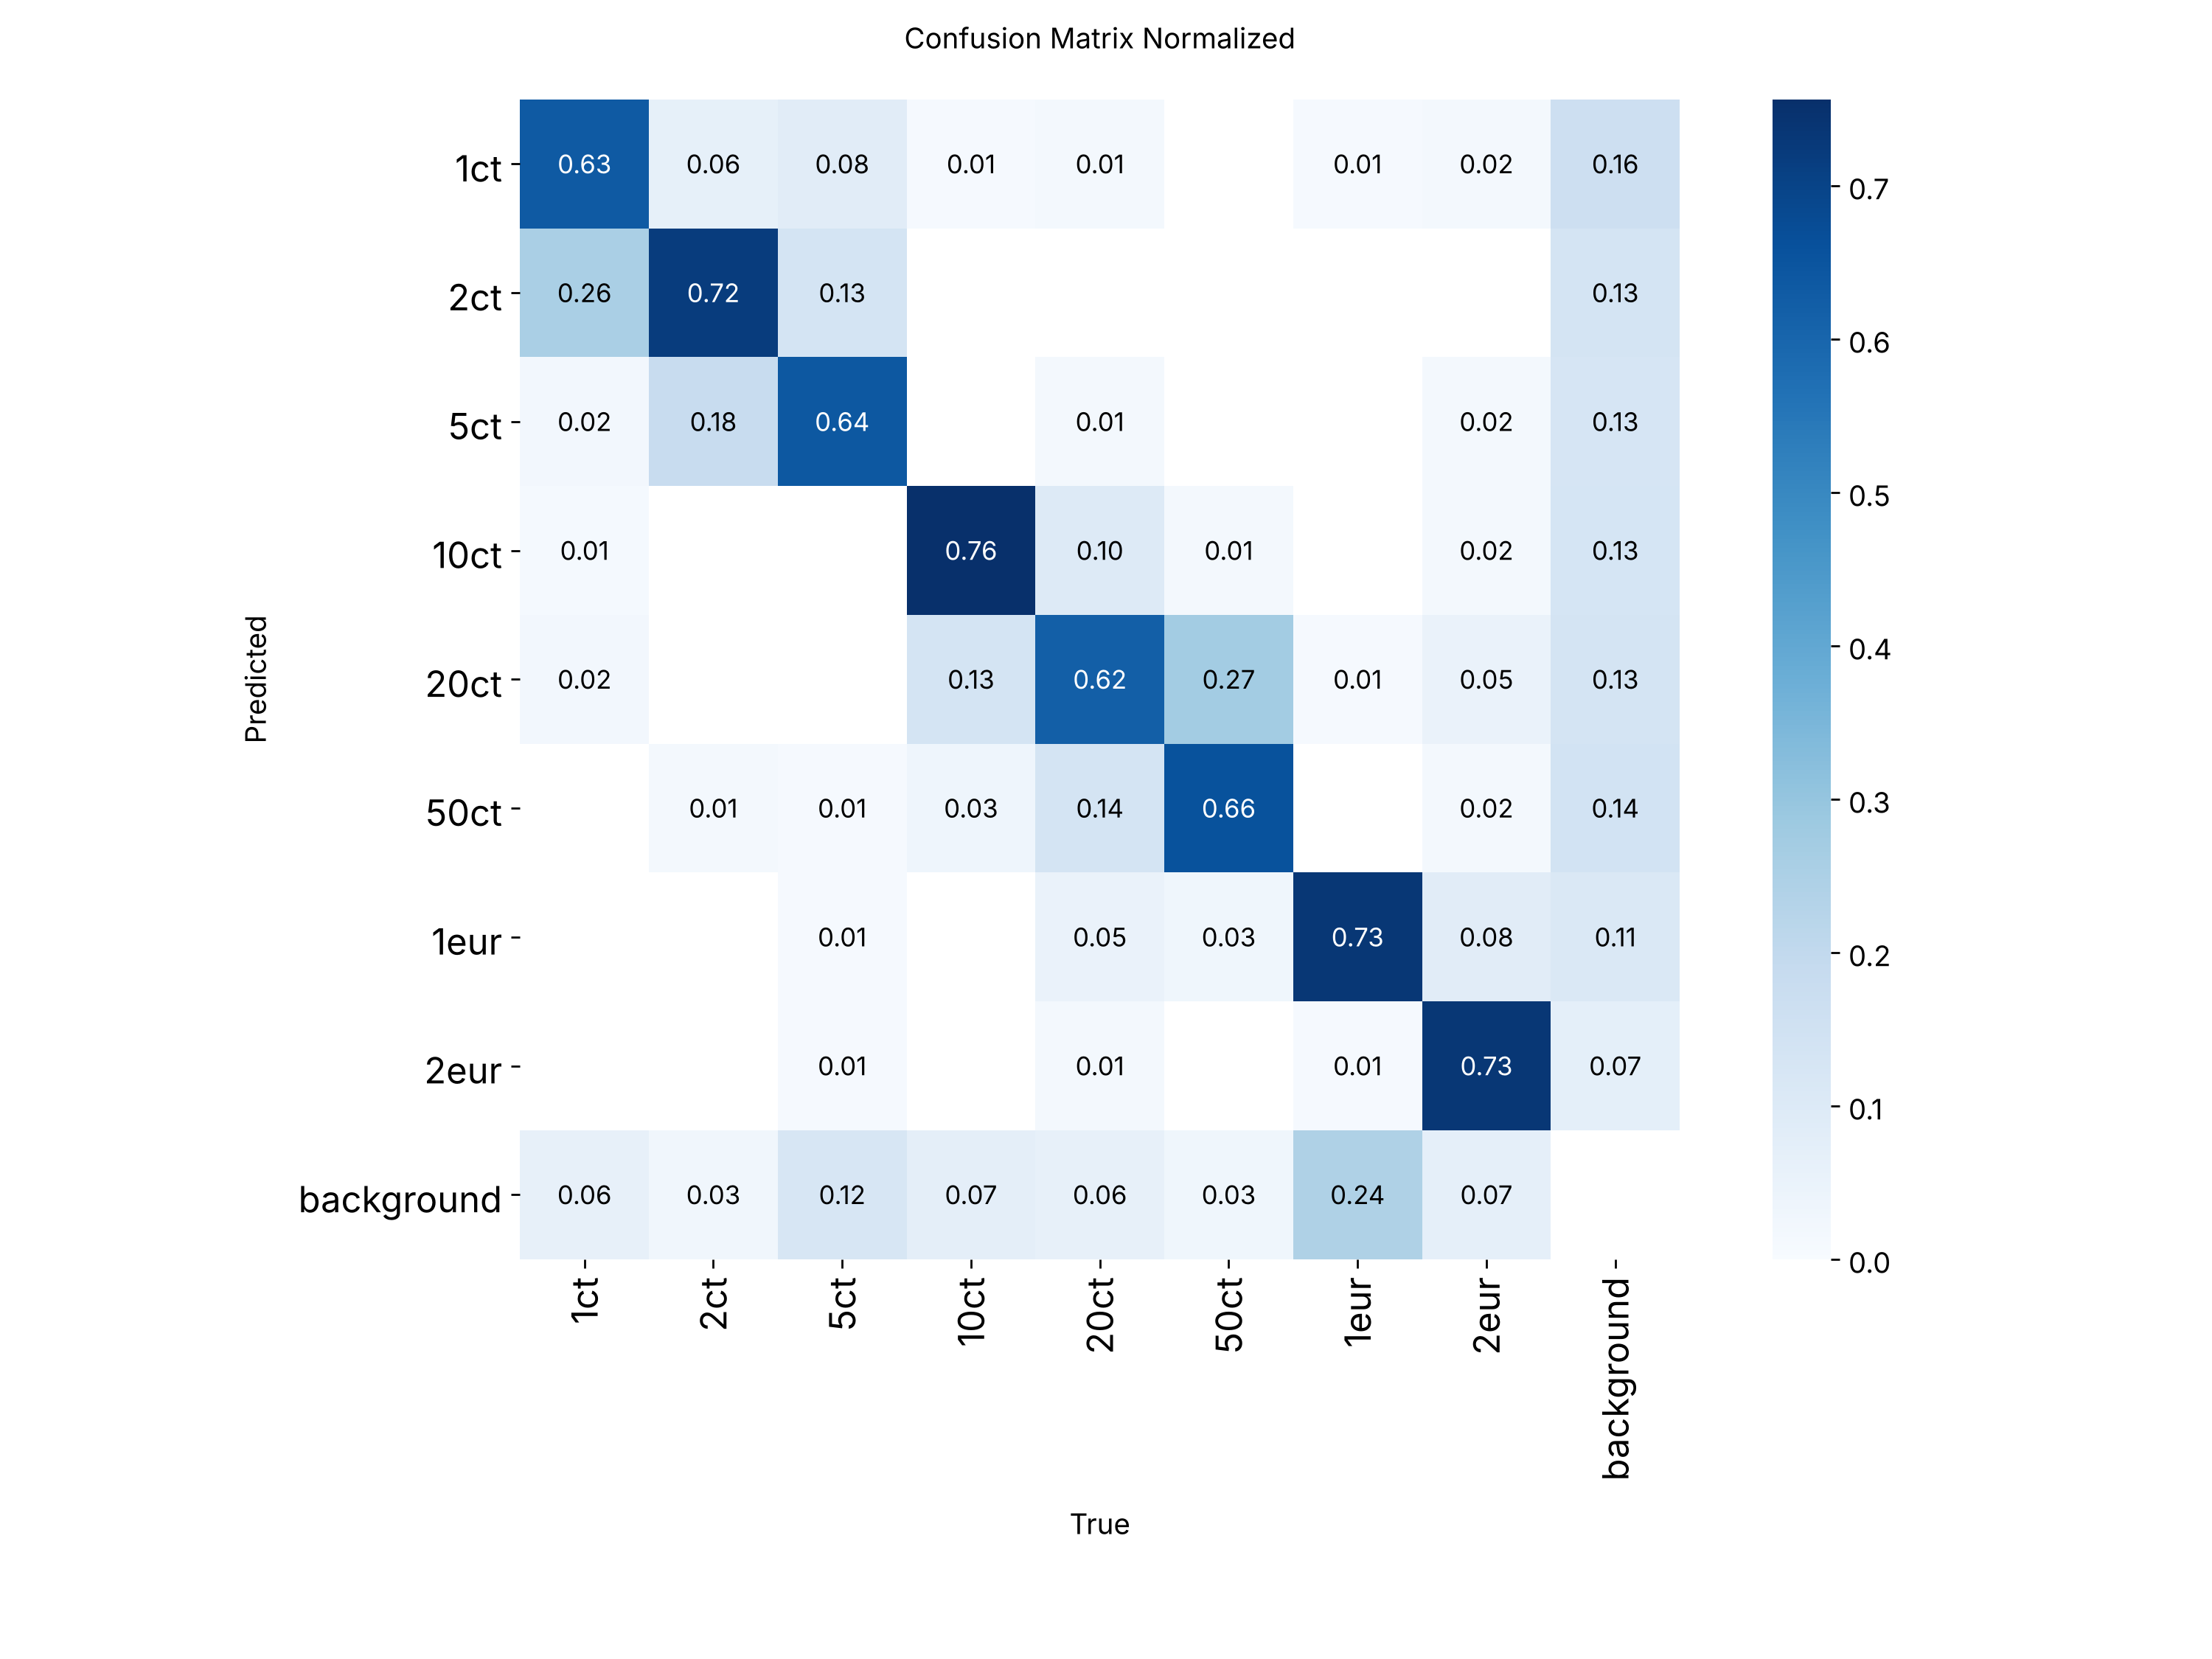

In [6]:
from IPython.display import Image, display

display(Image(filename=Path(metrics.save_dir) / "confusion_matrix_normalized.png", width=650))

## 3. Stimmt der Betrag?

Für den KI-Geldzähler zählt am Ende, ob die **Summe** stimmt. Wir vergleichen pro Testbild den erkannten mit dem tatsächlichen Betrag.

In [7]:
VALUES = {"1ct": 0.01, "2ct": 0.02, "5ct": 0.05, "10ct": 0.10,
          "20ct": 0.20, "50ct": 0.50, "1eur": 1.00, "2eur": 2.00}
NAMES = list(VALUES)
test = Path(DATA).parent / "images" / "test"

rows = []
for image in sorted(test.glob("*.jpg")):
    label = Path(str(image).replace("images", "labels")).with_suffix(".txt")
    label_lines = [z for z in label.read_text().splitlines() if z.strip()] if label.exists() else []
    true_sum = sum(VALUES[NAMES[int(z.split()[0])]] for z in label_lines)
    r = model.predict(image, conf=0.5, agnostic_nms=True, verbose=False)[0]
    detected_sum = sum(VALUES[r.names[int(c)]] for c in r.boxes.cls)
    rows.append({"image": image.name, "true_sum": true_sum, "detected_sum": detected_sum})

register_df = pd.DataFrame(rows)
register_df["error"] = (register_df.detected_sum - register_df.true_sum).round(2)
print(f"Betrag exakt richtig: {(register_df.error == 0).mean():.0%} der Testbilder")
register_df.sort_values("error", key=abs, ascending=False).head(8)

Betrag exakt richtig: 52% der Testbilder


,image,true_sum,detected_sum,error
55,IMG_4200_JPG_jpg.jpg,31.00,0.00,-31.00
54,IMG_4196_JPG_jpg.jpg,20.00,2.50,-17.50
90,test_19_JPG_jpg.jpg,0.00,16.52,16.52
88,test_17_JPG_jpg.jpg,0.00,13.61,13.61
101,test_9_jpg.jpg,13.45,0.00,-13.45
102,train_18_jpg.jpg,13.45,0.00,-13.45
98,test_6_jpg.jpg,10.25,0.00,-10.25
99,test_7_jpg.jpg,10.20,0.00,-10.20
